<a href="https://colab.research.google.com/github/pejmanrasti/SMART_MICROSCOPY/blob/main/TP2/TP2_Etudiant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learning to Scan — Q-learning for Smart Microscopy
### Main TP (35 min) + optional DMD extension (15 min) + uncertainty (10 min)

**Student version** — complete the `TODO` lines.  Python: NumPy + Matplotlib only. No GPU, microscope or external data required.

**Part A:** Navigate a 5 × 5 virtual sample and acquire a known target detected by *scout imaging*.

**Part B (extension):** Control a simulated **Digital Micromirror Device (DMD)** using programmable binary illumination masks. Learn to discover hidden regions of interest while limiting illumination dose.

The DMD experiment is a **didactic simulator**: a 2 × 2 grid stands in for four illumination regions. Photon counts, optical transfer, photobleaching kinetics and real device timing are *not* modelled.

## Part A — 0–5 min | A microscope that moves and acquires

A fast survey (*scout image*) tells us that the region of interest (ROI) lies at position `(3, 4)`. Our microscope stage begins at `(0, 0)`. Its actions are **UP**, **DOWN**, **LEFT**, **RIGHT**, **ACQUIRE**.

- Successful acquisition: **+10**; acquisition in the wrong place: **−3**.
- Normal stage movement: **−0.2**; blocked movement: **−1**.
- End an episode when the target is acquired or after **60 actions**.

**Question:** Does this first task require knowing an uncertainty map? Why or why not?

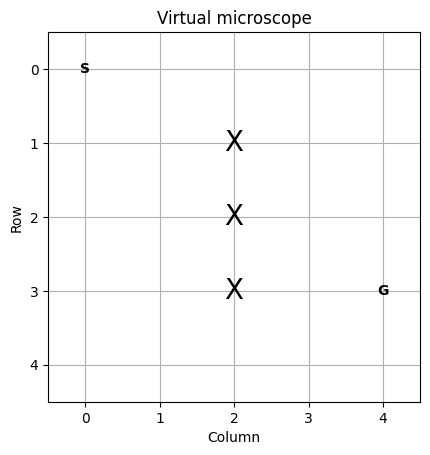

Initial state: 0 target: (3, 4)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SIZE = 5
START = (0, 0)
TARGET = (3, 4)
OBSTACLES = {(1, 2), (2, 2), (3, 2)}
ACTION_NAMES = ("UP", "DOWN", "LEFT", "RIGHT", "ACQUIRE")
DELTAS = ((-1, 0), (1, 0), (0, -1), (0, 1))
N_ACTIONS = len(ACTION_NAMES)
MAX_STEPS = 60

class MicroscopeGrid:
    def __init__(self):
        self.reset()

    def reset(self):
        self.position = START
        self.steps = 0
        return self.state

    @property
    def state(self):
        r, c = self.position
        return SIZE * r + c

    def step(self, action):
        if not 0 <= action < N_ACTIONS:
            raise ValueError("Invalid action")
        self.steps += 1
        if action == 4:  # ACQUIRE
            success = self.position == TARGET
            reward = 10.0 if success else -3.0
        else:
            dr, dc = DELTAS[action]
            r, c = self.position
            next_pos = (r + dr, c + dc)
            inside = all(0 <= v < SIZE for v in next_pos)
            if inside and next_pos not in OBSTACLES:
                self.position = next_pos
                reward = -0.2
            else:
                reward = -1.0
            success = False
        done = success or self.steps >= MAX_STEPS
        return self.state, reward, done, {"success": success}

def plot_grid(path=None, title="Virtual microscope"):
    fig, ax = plt.subplots(figsize=(4.8, 4.8))
    ax.set_xlim(-0.5, SIZE-0.5); ax.set_ylim(SIZE-0.5, -0.5)
    ax.set_xticks(range(SIZE)); ax.set_yticks(range(SIZE)); ax.grid(True)
    for r,c in OBSTACLES:
        ax.text(c,r,"X", ha="center", va="center", fontsize=20)
    ax.text(START[1],START[0],"S",ha="center",va="center",weight="bold")
    ax.text(TARGET[1],TARGET[0],"G",ha="center",va="center",weight="bold")
    if path is not None and len(path)>1:
        ax.plot([c for r,c in path],[r for r,c in path],marker="o")
    ax.set_title(title); ax.set_xlabel("Column"); ax.set_ylabel("Row")
    plt.show()

world = MicroscopeGrid()
plot_grid()
print("Initial state:",world.reset(),"target:",TARGET)

## Part A — 5–15 min | Implement Q-learning

An agent holds one value for each `(state, action)` pair, in a table `Q` of shape `(25, 5)`.

**Exercise A:** implement an ε-greedy policy: random action with probability ε; otherwise use the action with the highest Q value.

**Exercise B:** implement the Q-learning update, taking care that terminal states have no future-value bootstrap.

\[
Q(s,a)\leftarrow Q(s,a)+\alpha\big[r+\gamma(1-\text{done})\max_{a'}Q(s',a')-Q(s,a)\big]
\]

In [ ]:
def epsilon_greedy(Q, state, epsilon, rng):
    # TODO A: sample one random action with probability epsilon.
    # TODO A: otherwise return the action that maximizes Q[state, :].
    raise NotImplementedError("Complete epsilon_greedy")

def q_learning_update(Q, state, action, reward, next_state, done, alpha, gamma):
    # TODO B: implement the Q-learning update in-place.
    # Hint: bootstrap = 0.0 if done else gamma * max(Q[next_state])
    raise NotImplementedError("Complete q_learning_update")

In [ ]:
# Quick unit checks: fix the two functions above until both assertions pass.
test_rng = np.random.default_rng(7)
Qtest = np.zeros((25, 5)); Qtest[0, 2] = 5.0
assert epsilon_greedy(Qtest, 0, 0.0, test_rng) == 2
Qtest2 = np.zeros((25, 5)); Qtest2[1, 0] = 2.0
q_learning_update(Qtest2, 0, 1, reward=1., next_state=1,
                  done=False, alpha=0.5, gamma=0.9)
assert np.isclose(Qtest2[0,1], 1.4)
print("Both checks passed.")

## Part A — 15–25 min | Train and visualise

Train for 1,800 episodes. The exploration probability decreases over time but remains at least 0.05. Visualise the moving-average reward and the trajectory of the learned policy.

In [ ]:
def train_stage(n_episodes=1800, alpha=0.30, gamma=0.95,
                epsilon_decay=0.995, seed=2026):
    rng = np.random.default_rng(seed)
    env = MicroscopeGrid()
    Q = np.zeros((SIZE*SIZE, N_ACTIONS))
    rewards, successes, lengths = [], [], []
    for episode in range(n_episodes):
        state = env.reset(); ep_reward = 0.0
        eps = max(0.05, epsilon_decay**episode)
        for t in range(MAX_STEPS):
            action = epsilon_greedy(Q, state, eps, rng)
            ns, r, done, info = env.step(action)
            q_learning_update(Q, state, action, r, ns, done, alpha, gamma)
            ep_reward += r; state = ns
            if done: break
        rewards.append(ep_reward); successes.append(info["success"]); lengths.append(t+1)
    return Q, np.asarray(rewards), np.asarray(successes), np.asarray(lengths)

def moving_average(x, window=100):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(window)/window, mode="valid")

Q_stage, rewards, successes, steps = train_stage()
print(f"Last 100: reward={rewards[-100:].mean():.2f}; "
      f"success={successes[-100:].mean():.1%}; actions={steps[-100:].mean():.1f}")
fig, ax = plt.subplots(figsize=(8,3))
ax.plot(np.arange(99,len(rewards)), moving_average(rewards))
ax.set(xlabel="Training episode",ylabel="Mean reward (100 episodes)",title="Stage controller learning curve")
ax.grid(True); plt.show()

In [ ]:
SYMBOLS=("U", "D", "L", "R", "A")
def show_stage_policy(Q):
    for row in range(SIZE):
        cells=[]
        for col in range(SIZE):
            p=(row,col)
            cells.append("#" if p in OBSTACLES else
                         "G" if p == TARGET else SYMBOLS[int(np.argmax(Q[row*SIZE+col]))])
        print(" ".join(cells))

def stage_rollout(Q=None, seed=0):
    env=MicroscopeGrid(); s=env.reset(); rng=np.random.default_rng(seed)
    path=[env.position]; reward_sum=0
    for t in range(MAX_STEPS):
        action=int(rng.integers(N_ACTIONS)) if Q is None else int(np.argmax(Q[s]))
        s,r,done,info=env.step(action)
        reward_sum+=r; path.append(env.position)
        if done:break
    return info["success"],reward_sum,t+1,path

show_stage_policy(Q_stage)
found,score,n,path=stage_rollout(Q_stage)
plot_grid(path,"Policy learned by Q-learning")
print("Success:",found,"| actions:",n,"| reward:",round(score,2))

## Part A — 25–35 min | Compare and interpret

Change `gamma` or `epsilon_decay` and run a second training. Compare the **greedy** trained policy to a uniformly random baseline, evaluating with **no exploration** for the trained agent.

**Questions:**
1. What does \(\gamma\) control? What changes if blocked moves become expensive?
2. Why is the first problem navigation to a **known target**, not yet adaptive discovery?

In [ ]:
def evaluate_stage(Q=None, n=200):
    vals=[stage_rollout(Q, seed=i) for i in range(n)]
    return np.mean([x[0] for x in vals]),np.mean([x[2] for x in vals]),np.mean([x[1] for x in vals])

for name, q in [("Random",None),("Learned Q",Q_stage)]:
    sr,nm,rew=evaluate_stage(q)
    print(f"{name:10} | success {sr:6.1%} | actions {nm:5.1f} | reward {rew:6.2f}")

# Optional parameter experiment:
# Q_slow, *_ = train_stage(gamma=0.60, seed=2026)
# print(evaluate_stage(Q_slow))

---
## Part B — Optional extension (15 min) | DMD-based adaptive illumination

A **Digital Micromirror Device** controls **binary illumination patterns**, not mechanical stage positions. Simulate a 2 × 2 field of view containing four candidate regions.

- **Hidden sample:** one or more fluorescent targets; the real distribution is unknown to the agent.
- **State:** for each region, *unmeasured* (?), *measured negative* (0), or *measured positive* (1), and a remaining acquisition budget.
- **Actions:** illuminate a **single region** (4 actions), illuminate the **entire field** (1 action), or **STOP** (1 action).
- **Measurements:** illumination reveals the binary target state only in the illuminated regions (idealised, noiseless).
- **Reward:** reward discovering new targets; penalise illuminated area and repeated illumination. The cost is a simple **dose proxy**, not a phototoxicity model.

**Essential point:** the agent must NOT see the hidden target map before illumination. The state encodes only observations revealed by previous actions.

In [ ]:
# Five binary DMD illumination masks + STOP (sixth action).
DMD_MASKS = np.array([
    [1,0,0,0], [0,1,0,0], [0,0,1,0], [0,0,0,1],
    [1,1,1,1]
], dtype=bool)
DMD_NAMES = ("upper-left", "upper-right", "lower-left", "lower-right", "full-field", "STOP")
DMD_BUDGET = 3

# A synthetic *historical* prior on spatially correlated target configurations.
# Unknown to the agent during an episode; episodes are sampled from this distribution.
DMD_TEMPLATES = np.array([
    [1,0,0,0], [0,0,1,0], [1,0,1,0],
    [0,1,0,0], [0,0,0,1], [0,1,0,1],
    [0,1,1,0], [1,1,0,0], [0,0,1,1]
],dtype=np.int8)
DMD_WEIGHTS = np.array([.20,.17,.17,.10,.07,.07,.07,.08,.07])
assert np.isclose(DMD_WEIGHTS.sum(),1.)

def show_dmd_patterns():
    fig, axes=plt.subplots(1,5,figsize=(10,2.2))
    for i,ax in enumerate(axes):
        ax.imshow(DMD_MASKS[i].reshape(2,2),vmin=0,vmax=1,cmap="gray_r")
        ax.set_title(DMD_NAMES[i],fontsize=9)
        ax.set_xticks([]);ax.set_yticks([])
    plt.suptitle("Binary DMD patterns (white = illuminated)")
    plt.tight_layout();plt.show()

show_dmd_patterns()

### Part B — 1. Build the acquisition reward

A DMD action has a benefit and a cost:

\[
r = 1.5\times (\text{new targets detected})
    - 0.20\times (\text{local illuminated regions})
    - 0.28\times (\text{full-field illuminated regions})
    - 0.35\times (\text{regions illuminated again}).
\]

Only one of the `local` or `full-field` costs applies to a given action. `STOP` has reward 0 and ends the episode. An episode ends after at most 3 illumination actions.

**Exercise C:** implement the illumination reward and explain why illuminating the whole field is not always optimal.

In [ ]:
def dmd_reward(new_targets, illumination, already_observed, action):
    # TODO C: implement the formula given above.
    # Hint: `np.sum` counts True cells in Boolean masks.
    raise NotImplementedError("Complete dmd_reward")

In [ ]:
# Small deterministic check for the reward function.
assert np.isclose(dmd_reward(np.array([True,False,False,False]),
                              np.array([True,False,False,False]),
                              np.zeros(4,dtype=bool),0),1.30)
assert np.isclose(dmd_reward(np.zeros(4,dtype=bool),
                              np.ones(4,dtype=bool),
                              np.zeros(4,dtype=bool),4),-1.12)
print("DMD reward checks passed")

In [ ]:
def encode_dmd_observation(obs, remaining):
    """Four ternary observed values in {-1, 0, 1}, plus remaining budget."""
    code = 0
    for i,v in enumerate(obs):
        code += int(v+1)*3**i
    return int(code+81*remaining)

def dmd_posterior(obs):
    """Optional display: P(target in each tile | measurements), using a synthetic prior."""
    consistent = np.all((obs[None,:] < 0) | (DMD_TEMPLATES == obs[None,:]),axis=1)
    w = DMD_WEIGHTS * consistent
    if np.sum(w) == 0: return np.full(4,np.nan)
    w = w / np.sum(w)
    return w @ DMD_TEMPLATES

class DMDWorld:
    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)

    def reset(self):
        i=self.rng.choice(len(DMD_TEMPLATES),p=DMD_WEIGHTS)
        self._hidden_targets = DMD_TEMPLATES[i].astype(bool).copy()
        self.obs=np.full(4,-1,dtype=np.int8)
        self.budget=DMD_BUDGET
        self.dose=0.0;self.found=0
        return self.state

    @property
    def state(self):
        return encode_dmd_observation(self.obs,self.budget)

    def step(self, action):
        if not 0 <= action <= 5:
            raise ValueError("DMD action must be 0..5")
        if action == 5 or self.budget <= 0:
            return self.state,0.0,True,{"found":self.found,"dose":self.dose}
        illuminated=DMD_MASKS[action]
        already=self.obs!=-1
        revealed=illuminated & ~already
        new_found=revealed & self._hidden_targets
        reward=dmd_reward(new_found,illuminated,already,action)
        self.obs[illuminated]=self._hidden_targets[illuminated].astype(np.int8)
        base_cost=0.28 if action==4 else 0.20
        self.dose+=base_cost*np.sum(illuminated)
        self.found+=int(np.sum(new_found))
        self.budget-=1
        return self.state,reward,self.budget==0,{"found":self.found,"dose":self.dose}

# This simulator deliberately exposes only `obs` in its public state.
# The private `_hidden_targets` variable is for generating observations and
# MUST NOT be accessed by the policy.
dmd=DMDWorld(seed=14)
dmd.reset()
print("Prior target probability (2×2):\n",np.round(dmd_posterior(dmd.obs).reshape(2,2),2))
s,r,done,info=dmd.step(0)
print("Measurements after upper-left illumination:\n",dmd.obs.reshape(2,2))
print("Updated probabilities:\n",np.round(dmd_posterior(dmd.obs).reshape(2,2),2))

### Part B — 2. Reuse Q-learning for illumination control

The **same Q-learning update** now optimises a different instrument. The Q-table has 324 states (`81 possible observation patterns × 4 remaining-budget values`) and 6 actions.

The agent sees only the **updated observation** after each DMD illumination. The training simulator provides rewards, as a real experiment might provide an event detector or a reconstructed information score.

In [ ]:
def train_dmd(n_episodes=12000, alpha=0.15, gamma=0.92, seed=17):
    rng=np.random.default_rng(seed)
    env=DMDWorld(seed=seed+1)
    Q=np.zeros((81*(DMD_BUDGET+1),6))
    returns=[]
    for episode in range(n_episodes):
        s=env.reset(); total=0.0
        eps=max(0.05,0.80*(0.99955**episode))
        for t in range(DMD_BUDGET+1):
            a=epsilon_greedy(Q,s,eps,rng)
            ns,r,done,info=env.step(a)
            q_learning_update(Q,s,a,r,ns,done,alpha,gamma)
            total+=r;s=ns
            if done: break
        returns.append(total)
    return Q,np.asarray(returns)

Q_dmd, dmd_returns = train_dmd()
fig,ax=plt.subplots(figsize=(7,3))
ax.plot(np.arange(199,len(dmd_returns)),moving_average(dmd_returns,200))
ax.set(title="DMD controller: learning curve",xlabel="Training episode",ylabel="Mean return (200 episodes)")
ax.grid(True);plt.show()

In [ ]:
def evaluate_dmd(Q=None, n=500, seed=110):
    # Matched test samples by seed for both policies.
    returns=[];detections=[];doses=[];steps=[]
    for i in range(n):
        env=DMDWorld(seed=seed+i)
        s=env.reset();rng=np.random.default_rng(seed+10000+i)
        ep_ret=0.0
        for t in range(DMD_BUDGET+1):
            a=int(rng.integers(6)) if Q is None else int(np.argmax(Q[s]))
            ns,r,done,info=env.step(a)
            ep_ret+=r;s=ns
            if done:break
        returns.append(ep_ret);detections.append(info["found"])
        doses.append(info["dose"]);steps.append(t+1)
    return np.array([np.mean(returns),np.mean(detections),np.mean(doses),np.mean(steps)])

print("                     Return   Found   Dose   Actions")
for name,Q_ in [("Random DMD patterns",None),("Learned DMD policy",Q_dmd)]:
    v=evaluate_dmd(Q_)
    print(f"{name:22} {v[0]:6.2f} {v[1]:7.2f} {v[2]:6.2f} {v[3]:7.2f}")

### Part B — Discussion

1. Why can the agent **not** use the real hidden fluorescence map in its state?
2. Why is a DMD policy different from simply moving the microscope stage?
3. Which optical factors would be required to replace the toy dose cost with a realistic model (illumination irradiance, exposure time, DMD efficiency, photobleaching kinetics, SNR, etc.)?
4. Does the Q-learning reward measure information gain, cell survival or image quality? **No:** it rewards target discovery and uses a simplified dose proxy.
5. Which experimental measurements (scout image, PSF/noise calibration, sparse fluorescence observations) would help obtain a more realistic predictive uncertainty?

**Extra challenge:** remove the full-field pattern and retrain. Does a restricted DMD action library improve or worsen the expected reward? How does the answer change with the illumination penalty?

**Take-home:** In Part A the agent chooses *where the stage moves*. In Part B it chooses *how light interacts with the sample*. Both are instrument-control actions, but only Part B performs adaptive optical probing of initially unknown regions.

---
## Part C — Optional extension (+10 min) | Uncertainty-aware DMD sampling

The DMD experiment does not know which tiles contain a fluorescent target until they have been illuminated. It must therefore maintain a **belief** about the hidden sample.

A synthetic prior over nine target configurations (`DMD_TEMPLATES`, `DMD_WEIGHTS`) represents historical knowledge, potentially derived from *fast scout images* in a real microscope. As new tile measurements arrive, we discard templates incompatible with the observed responses and renormalise the remaining weights.

**1. Uncertainty map.** If $p_j=P(T_j=1\mid D_t)$ is the probability of a target in tile $j$, define the binary entropy in bits:

$$H_j=-p_j\log_2 p_j-(1-p_j)\log_2(1-p_j).$$

$H_j=1$ bit is maximally uncertain; $H_j=0$ means the state is known (under this toy prior). We set $0\log 0=0$.

**2. Choosing an illumination pattern.** With noiseless measurements, the information gain from illuminating mask $M$ is:

$$\mathrm{EIG}(M\mid D_t)=H(Y_M\mid D_t),$$

where $Y_M$ is the **joint** binary outcome of all illuminated tiles. The joint entropy matters: **summing tile entropies is generally wrong when targets are correlated**. A cost-aware choice maximises:

$$a^*=\arg\max_{a\in\{0,1,2,3,4,\mathrm{STOP}\}}\big[\mathrm{EIG}(a\mid D_t)-\lambda C(a,D_t)\big].$$

**Exercise D (3 min):** plot the target probability and tile-entropy maps before and after a local illumination. Do not show or use `env._hidden_targets` in your decision rule.

**Exercise E (5 min):** implement a *cost-aware information-gain baseline* that uses the posterior over templates, then compare it with Q-learning and random illumination. Use the same episodes and reward function.

**Discussion (2 min):** Q-learning was trained to **discover targets while reducing dose**; the information-gain baseline seeks to **reduce uncertainty**. Why can they choose different illumination patterns? Does high uncertainty imply high biological value?

**Connection to TP1:** MC Dropout on a U-Net gives a **model-disagreement proxy** for a fluorescence prediction. Here uncertainty is **Bayesian uncertainty about the unmeasured binary target map**, conditioned on an explicit prior. These are distinct quantities. A real system could use scout imaging or a calibrated neural predictor to inform the prior before DMD probing.

*Idealised setting:* noiseless binary measurements; a correct finite prior; toy dose units. No noise, PSF, fluorescent intensity or photobleaching kinetics are modelled.

In [ ]:
# Posterior helper functions are supplied; the two exercises are below.
def binary_entropy(p):
    """Binary entropy in bits; accepts scalar or NumPy array."""
    p=np.asarray(p,dtype=float)
    safe=np.clip(p,1e-12,1.-1e-12)
    h=-safe*np.log2(safe)-(1.-safe)*np.log2(1.-safe)
    return np.where((p<=0.) | (p>=1.),0.,h)


def posterior_weights(obs):
    """P(template | observed tiles), assuming the synthetic prior is correct."""
    obs=np.asarray(obs,dtype=np.int8)
    consistent=np.all((obs[None,:] < 0) | (DMD_TEMPLATES == obs[None,:]),axis=1)
    w=DMD_WEIGHTS*consistent
    if w.sum()==0:
        raise ValueError('observations incompatible with the synthetic prior')
    return w/w.sum()


def dmd_information_gain(obs, action):
    """Information gained (bits) by noiselessly observing a DMD pattern.

    Conditional entropy of the *joint* illuminated outcomes, accounting for
    correlations imposed by DMD_TEMPLATES. Does not access any hidden sample.
    """
    if action == 5: return 0.0  # STOP
    posterior=posterior_weights(obs)
    mask=DMD_MASKS[action]
    _, groups=np.unique(DMD_TEMPLATES[:,mask],axis=0,return_inverse=True)
    probs=np.bincount(groups,weights=posterior)
    probs=probs[probs>0]
    return float(-(probs*np.log2(probs)).sum())


def dmd_action_cost(obs, action):
    """Acquisition cost + repeated-illumination penalty, in toy units."""
    if action==5:return 0.
    mask=DMD_MASKS[action]
    return (0.28 if action==4 else 0.20)*float(mask.sum()) + 0.35*float((mask & (obs!=-1)).sum())


def info_greedy_action(obs, lam=1.0):
    """Return action maximizing expected information gain minus light cost.

    The STOP action has utility zero and wins if all remaining actions are
    uninformative or too expensive.
    """
    scores=np.array([dmd_information_gain(obs,a)-lam*dmd_action_cost(obs,a)
                     for a in range(5)] + [0.])
    return int(np.argmax(scores)),scores


# TODO D1. Create a new DMDWorld with a fixed seed and reset it.
# Display probabilities: dmd_posterior(env.obs).reshape(2,2)
# Display uncertainties: binary_entropy(dmd_posterior(env.obs)).reshape(2,2)
# Illuminate upper-left (action 0), then repeat both maps.
# Plot the two 2x2 maps with plt.imshow, vmin=0, vmax=1.

# TODO E1. Print expected information gain and total cost for all 6 actions
# at the first state. Compare full-field to local masks.

# TODO E2. Compare random, Q-learning and an information-greedy baseline:
# use evaluate_dmd(Q_dmd) and the optional evaluation function below.


In [ ]:
def evaluate_information_greedy(n=500,seed=110,lam=1.0):
    """Same held-out episodes and *target discovery reward* as evaluate_dmd."""
    returns=[];detections=[];doses=[];steps=[]
    for i in range(n):
        env=DMDWorld(seed=seed+i)
        s=env.reset(); ep_ret=0.
        for t in range(DMD_BUDGET+1):
            a,_=info_greedy_action(env.obs,lam=lam)
            _,r,done,info=env.step(a)
            ep_ret+=r
            if done:break
        returns.append(ep_ret);detections.append(info['found'])
        doses.append(info['dose']);steps.append(t+1)
    return np.array([np.mean(returns),np.mean(detections),np.mean(doses),np.mean(steps)])

# TODO E3. Print and compare evaluate_dmd(None), evaluate_dmd(Q_dmd),
# and evaluate_information_greedy() on 500 independent episodes.
